## **Explanatory Data Analysis (EDA)** ##

In [1]:
# Import libraries needed
import warnings

import numpy as np
import pandas as pd

# For graph plot
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
import plotly.graph_objects as go
from plotly.subplots import make_subplots

# Tests
from statsmodels.tsa.stattools import adfuller
from statsmodels.tsa.stattools import coint
from statsmodels.tsa.vector_ar.vecm import coint_johansen 
from statsmodels.stats.outliers_influence import variance_inflation_factor

In [2]:
# Ignore warnings
warnings.filterwarnings("ignore", category=UserWarning)

In [3]:
# Import data and settings
df = pd.read_csv("data_engineed.csv")
df["From"] = pd.to_datetime(df["From"])

mete_col = ["Diurnal temperature range (°C)", "Mean temperature (°C)", "Mean humidity (%)", "Solar radiation (MJ/m²)", "Air pressure (hPa)", "Dew point temperature (°C)", "Wind speed (km/h)", "Mean UV"]
flu_col = ["H1", "H3", "B", "AandB"]
control_col = ["Week", "ContainmentHealthIndex_Average", "pandemic_flag"]

---
### **1. Basic Information of the DataFrame**
**Interpretations**
- Variance is much larger than the mean for influenza case counts 
    -  Shows overdispersion (massive amount of a specific value in the corresponding column)
    -  Need to use Quasi-Poisson / Negative Binomial / Tweedie as the distribution family for DLNM to handle overdispersion


&emsp;**a. Overall review of the top few rows of the DataFrame**

In [4]:
# Quick overview of the data
df.head()

,Year,Week,From,Diurnal temperature range (°C),Mean temperature (°C),Mean humidity (%),Solar radiation (MJ/m²),Air pressure (hPa),Dew point temperature (°C),Wind speed (km/h),Mean UV,H1,H3,B,AandB,ContainmentHealthIndex_Average,pandemic_flag,sars_flag,Population,school_flag
0,2002,36,2002-09-01,14.3,28.15,76.5,19.66,1008.20,23.20,7.35,4.0,1,12,3.0,19,0.0,0.0,0.0,6725.8,1.0
1,2002,37,2002-09-08,13.6,26.70,85.0,9.35,1006.30,23.80,10.50,3.0,0,6,4.0,15,0.0,0.0,0.0,6725.8,1.0
2,2002,38,2002-09-15,11.2,26.40,83.0,16.75,1011.35,23.20,13.45,4.0,0,4,4.0,13,0.0,0.0,0.0,6725.8,1.0
3,2002,39,2002-09-22,10.0,25.90,85.0,10.93,1012.90,23.25,13.25,3.0,0,2,6.0,10,0.0,0.0,0.0,6725.8,1.0
4,2002,40,2002-09-29,10.6,25.95,82.0,11.56,1012.80,22.40,10.05,3.0,0,6,2.0,8,0.0,0.0,0.0,6725.8,1.0


&emsp;**b. Information of the DataFrame**


In [5]:
# Infromation of the DataFrmae
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1253 entries, 0 to 1252
Data columns (total 20 columns):
 #   Column                          Non-Null Count  Dtype         
---  ------                          --------------  -----         
 0   Year                            1253 non-null   int64         
 1   Week                            1253 non-null   int64         
 2   From                            1253 non-null   datetime64[ns]
 3   Diurnal temperature range (°C)  1253 non-null   float64       
 4   Mean temperature (°C)           1253 non-null   float64       
 5   Mean humidity (%)               1253 non-null   float64       
 6   Solar radiation (MJ/m²)         1253 non-null   float64       
 7   Air pressure (hPa)              1253 non-null   float64       
 8   Dew point temperature (°C)      1253 non-null   float64       
 9   Wind speed (km/h)               1253 non-null   float64       
 10  Mean UV                         1253 non-null   float64       
 11  H1  

&emsp;**c. Statistical information for columns of the independent, dependent, and control variables respectively**



In [6]:
# Statistical information for the meteorological data
df[mete_col].describe()

,Diurnal temperature range (°C),Mean temperature (°C),Mean humidity (%),Solar radiation (MJ/m²),Air pressure (hPa),Dew point temperature (°C),Wind speed (km/h),Mean UV
count,1253.000000,1253.000000,1253.000000,1253.000000,1253.000000,1253.000000,1253.000000,1253.000000
mean,14.864006,23.383599,78.736233,13.996983,1012.860774,19.225339,10.074062,2.891700
std,3.539967,5.005770,8.494599,5.270534,6.067874,5.963239,1.811932,1.256406
min,3.900000,8.900000,43.000000,2.020000,996.750000,-0.100000,5.550000,0.400000
25%,12.200000,19.100000,74.500000,9.930000,1008.000000,14.900000,8.800000,2.000000
50%,14.000000,24.400000,80.000000,14.240000,1012.800000,20.500000,10.000000,3.000000
75%,17.000000,28.000000,85.000000,17.680000,1017.650000,24.800000,11.200000,4.000000
max,27.700000,31.700000,94.000000,26.460000,1027.700000,26.800000,17.800000,7.000000


In [7]:
# Statistical information for the influenza data
df[flu_col].describe()

,H1,H3,B,AandB
count,1253.000000,1253.000000,1252.000000,1253.000000
mean,96.938547,115.727055,44.593450,261.437350
std,300.226983,233.728958,131.615377,439.621172
min,0.000000,0.000000,0.000000,0.000000
25%,1.000000,5.000000,3.000000,27.000000
50%,10.000000,28.000000,12.500000,103.000000
75%,63.000000,125.000000,41.000000,305.000000
max,4544.000000,2560.000000,1978.000000,4679.000000


In [8]:
# Statistical information for the control variables 
df[control_col].describe()

,Week,ContainmentHealthIndex_Average,pandemic_flag
count,1253.000000,1253.000000,1253.000000
mean,26.605746,8.128132,0.131684
std,15.077257,21.983305,0.338282
min,1.000000,0.000000,0.000000
25%,14.000000,0.000000,0.000000
50%,27.000000,0.000000,0.000000
75%,40.000000,0.000000,0.000000
max,53.000000,82.140000,1.000000


&emsp;**d. Missing value identification**

In [9]:
# Check missing values in each columns
print(f"Number of NA values in each rows: \n{df.isna().sum()}")

Number of NA values in each rows: 
Year                              0
Week                              0
From                              0
Diurnal temperature range (°C)    0
Mean temperature (°C)             0
Mean humidity (%)                 0
Solar radiation (MJ/m²)           0
Air pressure (hPa)                0
Dew point temperature (°C)        0
Wind speed (km/h)                 0
Mean UV                           0
H1                                0
H3                                0
B                                 1
AandB                             0
ContainmentHealthIndex_Average    0
pandemic_flag                     0
sars_flag                         0
Population                        0
school_flag                       0
dtype: int64


&emsp;**e. Zero value identification**

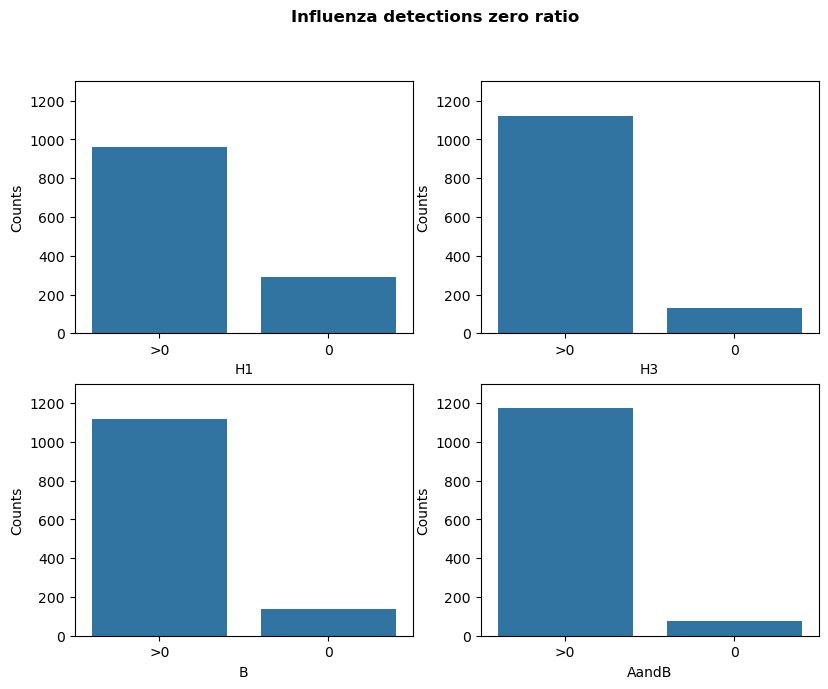

In [10]:
# Check how many 0 exists in the target variables
(df[flu_col]==0).sum()

# Visualize the ratio of counts
fig, axes = plt.subplots(2, 2, figsize=(6.4*1.5, 4.8*1.5))

for i, col in enumerate(flu_col):
    temp_df = pd.DataFrame(df[col], columns=[col])
    temp_df["zero_flag"] = (temp_df[col]==0).astype(int)
    sns.barplot(data=temp_df["zero_flag"].value_counts(), ax=axes[i//2, i%2])
    axes[i//2, i%2].set_xticklabels([">0", "0"])
    axes[i//2, i%2].set_xlabel(col)
    axes[i//2, i%2].set_ylabel("Counts")
    axes[i//2, i%2].set_ylim(0, 1300)

plt.suptitle("Influenza detections zero ratio", fontweight="bold")
plt.show()

--- 
### **2. Influenza Case Count Analysis**
Bar charts are used to find the difference of influenza cases in different months and seasons respectively

**Interpretations**
- Type AH3 influenza (145006) dominantes Hong Kong's flu season pattern, which is slightly more than type AH1 (121464). 
- Winter (99307) has the highest number of flu cases among the four seasons, following by Summer (94794). 
- 

In [11]:
# Add columns <Month> and <Seasonality>
df["Month"] = df["From"].dt.month

spring_index = df[((df["Month"] >= 3) & (df["Month"] <= 5))].index
summer_index = df[((df["Month"] >= 6) & (df["Month"] <= 8))].index
autumn_index = df[((df["Month"] >= 9) & (df["Month"] <= 11))].index
df.loc[spring_index, "Seasonality"] = "Spring"
df.loc[summer_index, "Seasonality"] = "Summer"
df.loc[autumn_index, "Seasonality"] = "Autumn"
df.fillna({"Seasonality": "Winter"}, inplace=True)

In [12]:
for col in ["H1", "H3", "B"]:
    print(f"Total {col} type influenza cases: {df[col].sum()}")

Total H1 type influenza cases: 121464
Total H3 type influenza cases: 145006
Total B type influenza cases: 55831.0


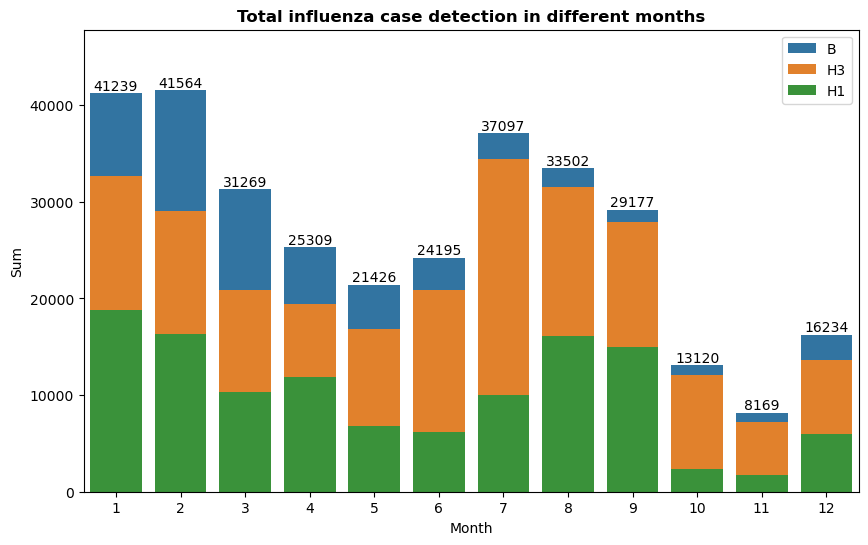

In [13]:
agg = df.groupby("Month", as_index=False)[["H1", "H3", "B"]].sum()

agg["H1_H3"] = agg["H1"] + agg["H3"]
agg["Total"] = agg["H1"] + agg["H3"] + agg["B"]

plt.figure(figsize=(10, 6))

ax = sns.barplot(agg, x="Month", y="Total", label="B")
sns.barplot(agg, x="Month", y="H1_H3", label="H3", ax=ax)
sns.barplot(agg, x="Month", y="H1", label="H1", ax=ax)

ax.bar_label(ax.containers[0])

ax.set_ylim(0, agg["Total"].max() * 1.15)
ax.set_ylabel("Sum")
ax.set_title("Total influenza case detection in different months", fontweight="bold")
ax.legend()
plt.show()

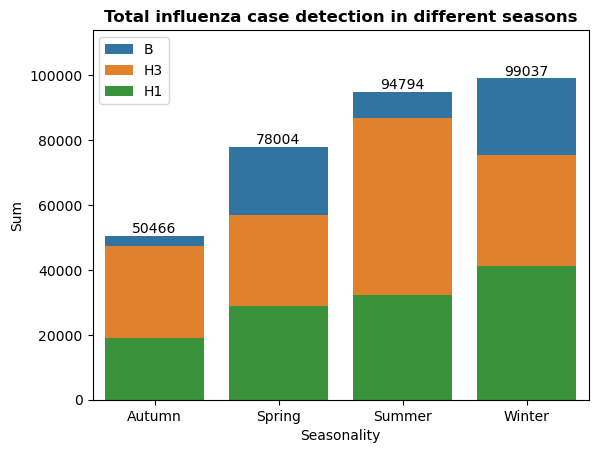

In [14]:
agg = df.groupby("Seasonality", as_index=False)[["H1", "H3", "B"]].sum()

agg["H1_H3"] = agg["H1"] + agg["H3"]
agg["Total"] = agg["H1"] + agg["H3"] + agg["B"]

ax = sns.barplot(agg, x="Seasonality", y="Total", label="B")
sns.barplot(agg, x="Seasonality", y="H1_H3", label="H3", ax=ax)
sns.barplot(agg, x="Seasonality", y="H1", label="H1", ax=ax)

ax.bar_label(ax.containers[0])

ax.set_ylim(0, agg["Total"].max() * 1.15)
ax.set_ylabel("Sum")
ax.set_title("Total influenza case detection in different seasons", fontweight="bold")
ax.legend()
plt.show()

---
### **3. Relation between influenza case counts and meteorlogical factors**
The scatterplot is used to identify the relationship between  meteorlogical data and influenza case counts for different types of influenza. 

The x-axis are the meterological data, while the y-axis represents different type of influenza. 

**Interpretations**

- Overdispersion exist by seeing that the majority of data points lie on the bottom of the graph with some points lying on the top of the graph. 
- All relationships are non-linear and heteroscedasticity.

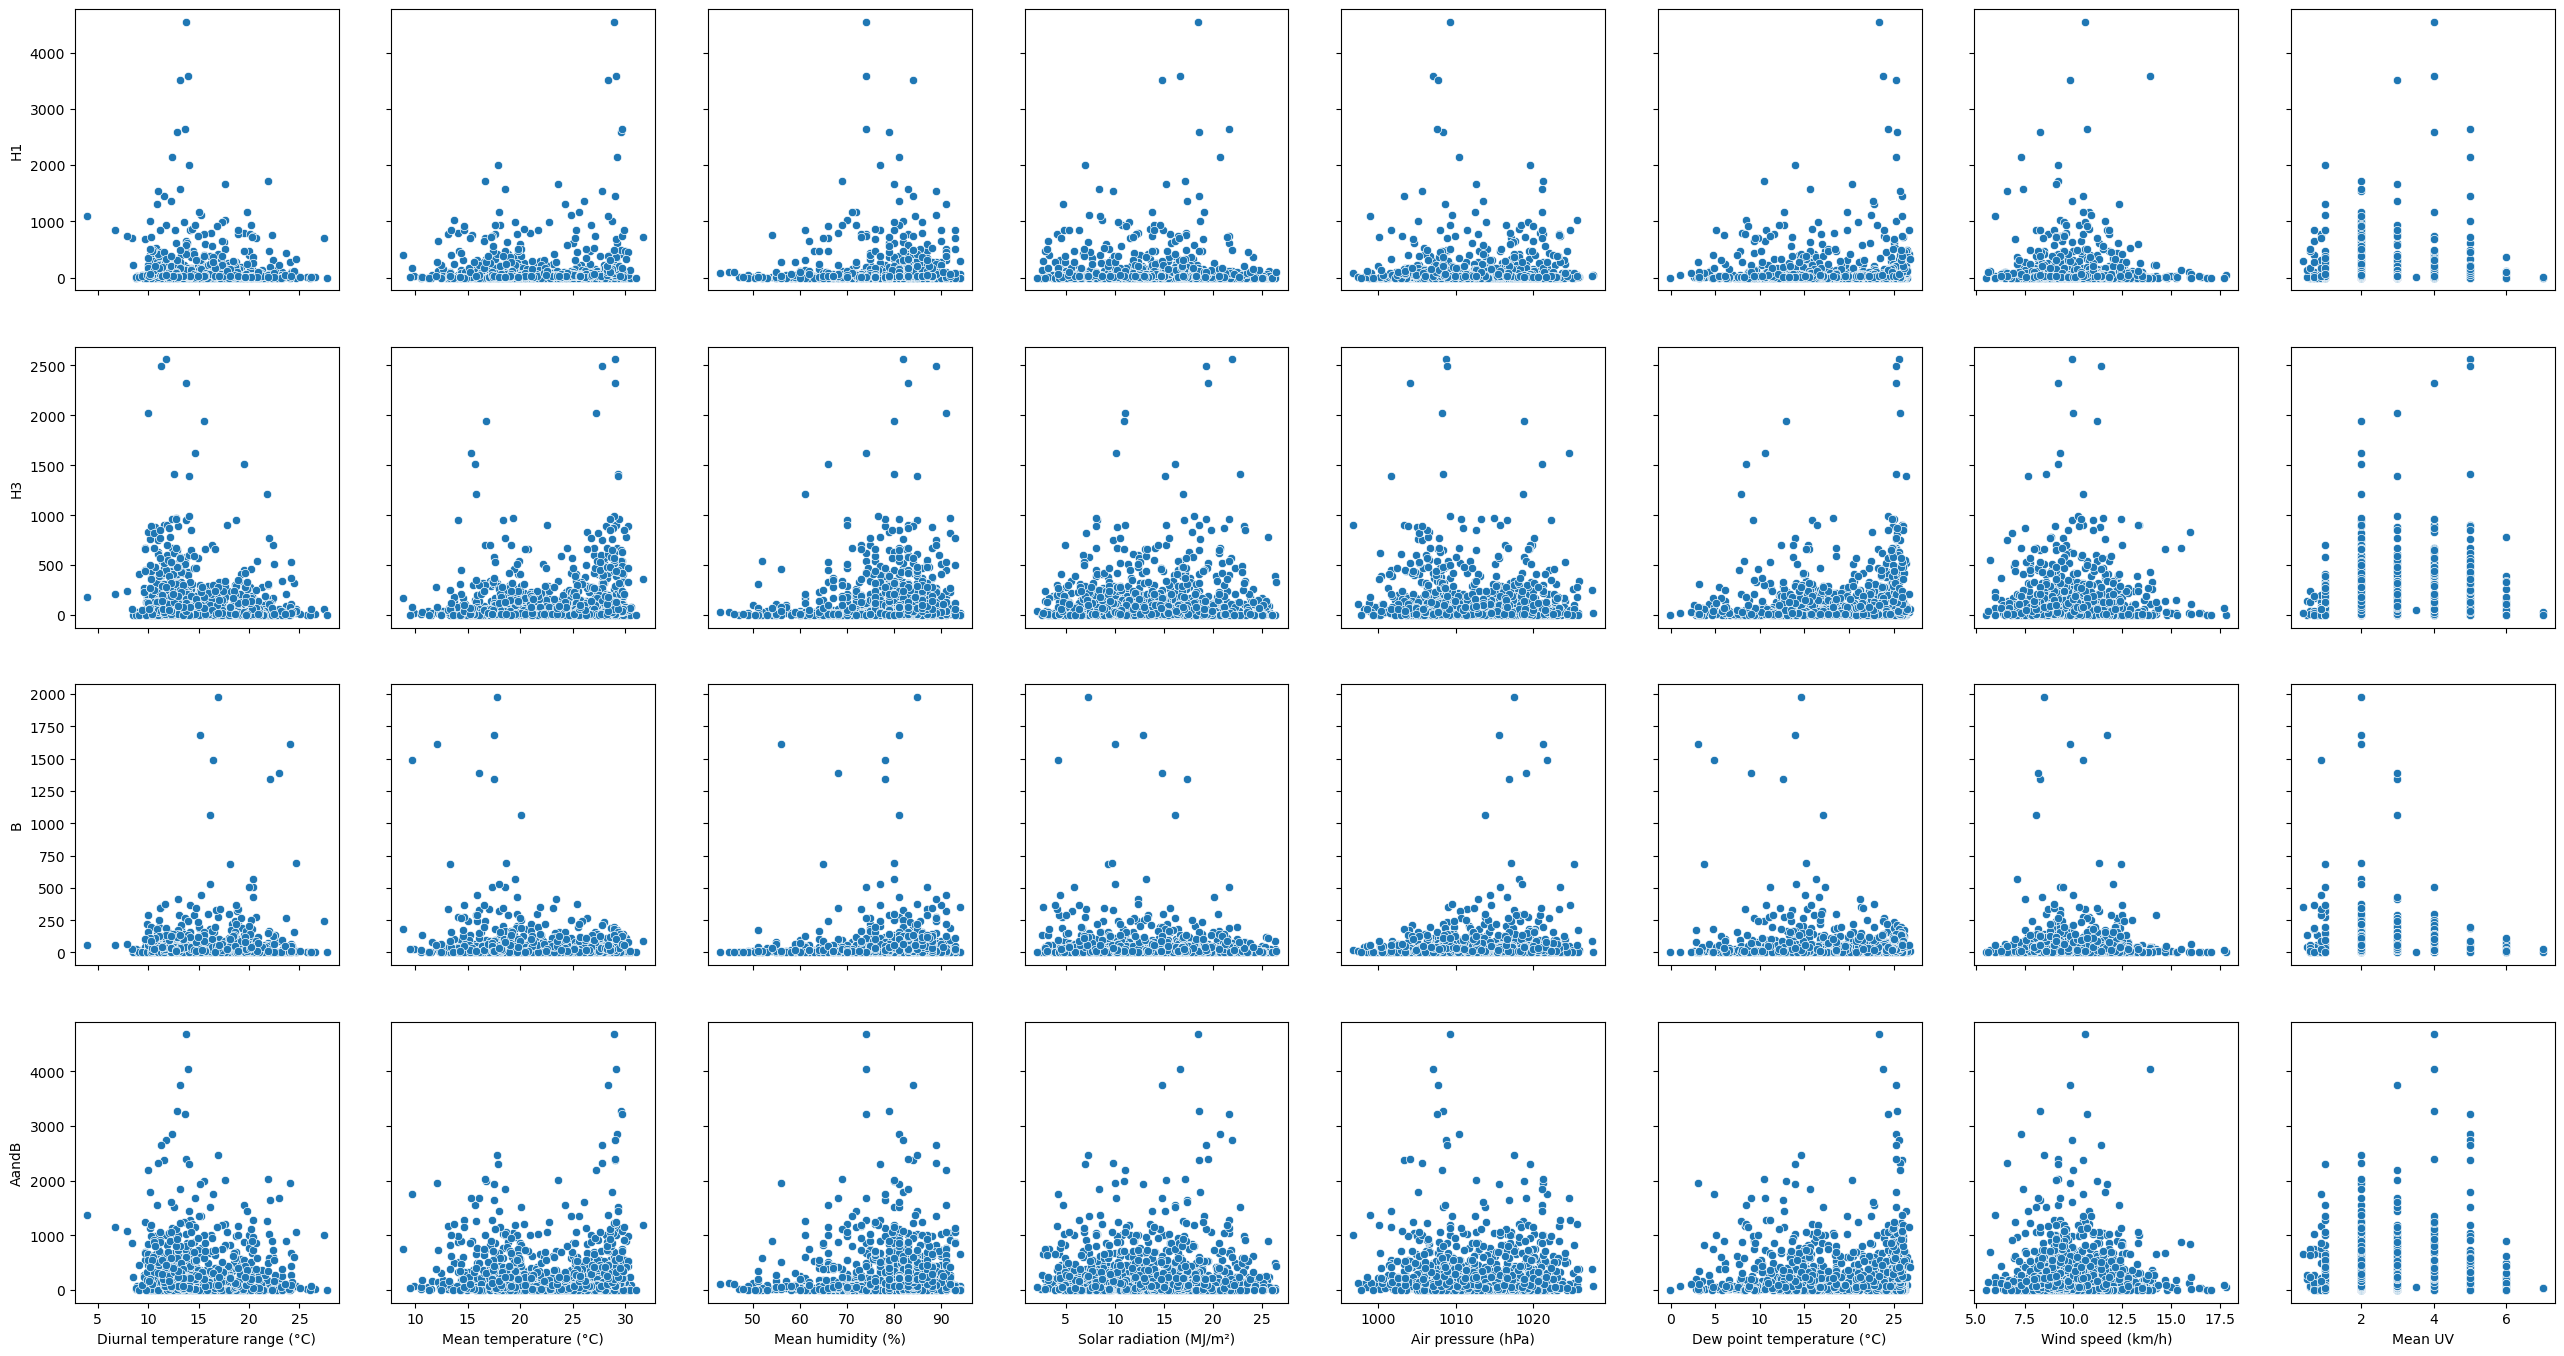

In [15]:
fig, axes = plt.subplots(4, 8, figsize=(6.4*5, 4.8*3.5))

for i, flu in enumerate(flu_col):
    for j, mete in enumerate(mete_col):
        sns.scatterplot(x=mete, y=flu, data=df, ax=axes[i, j])
        axes[i, j].set_xlabel(mete)
        axes[i, j].set_ylabel(flu)
        axes[i, j].label_outer()
        
plt.show()


---
### **4. Overall trends**
Line graphs are used to see the overall trend of influenza case counts in terms of types, and meteorological variables

**Interpretations**



In [16]:
# Line graph for influenza
df_long = df.melt(
    id_vars=["From"],
    value_vars=["H1", "H3", "B"],
    var_name="Type",  
    value_name="Influenza detections",  
)

fig = px.line(df_long, "From", "Influenza detections", color="Type",
              title="Number of detections based on timeline", 
              width=1500, height=600
             )

fig.show()

In [17]:
# Line graph for meteorological variables 
cols = mete_col
colors = ["#e15759","#b89b28","#59a14f","#1b9e77","#17a7e0","#8e7cc3","#e754a8"]
n = len(cols)

fig = make_subplots(
    rows=n, cols=1,
    shared_xaxes=True, vertical_spacing=0.02,
    specs=[[{"secondary_y": True}] for _ in range(n)],
)

for i, col in enumerate(cols, start=1):
    color = colors[(i - 1) % len(colors)]

    fig.add_trace(
        go.Scatter(
            x=df["From"], y=df[col], name=col, mode="lines",
            line={"color": color, "width": 1.2}, showlegend=True,
        ),
        row=i, col=1, secondary_y=False
    )

    fig.update_yaxes(
        row=i, col=1, secondary_y=False,
        showgrid=True, gridcolor="rgba(220, 220, 220, 0.7)", showline=True, linecolor="#888888", tickfont={"size": 10}
    )

    fig.update_yaxes(
        row=i, col=1, secondary_y=True,
        title_text=col, title_font={"size": 11, "color": "black"},
        showticklabels=False, showgrid=False, showline=True, linecolor="#888888"
    )

    fig.update_xaxes(
        row=i, col=1,
        showgrid=True, gridcolor="rgba(220, 220, 220, 0.7)",
        showline=True, linecolor="#888888",
        tickformat="%Y" if i == n else None, showticklabels=(i == n),
    )

fig.update_layout(
    title="Meteorological values based on timeline", width=1500, height=max(650, n * 100),
    plot_bgcolor="white", paper_bgcolor="white",
    margin={"l": 60, "r": 180, "t": 85, "b": 40}, hovermode="x unified"
)

fig.add_annotation(
    text="Variables", x=-0.04, y=0.5, xref="paper", yref="paper",
    textangle=-90, font={"size": 13, "color": "black"},
)

fig.show()

---
### **5. Correlations**
Heatmaps are used to visulaized the correlation matrix and show the correlation between different objects. Spearman rank correlation is used to to find the relationship as the default (Pearson's R) can only measure linear relationships , where Spearman rank correlation can be utilized for non-linear and non-monotonic (not moving in one direction) relationships. 

**Interpretations**

&emsp;**a. Overall correlation between meteorological factors and different types of influenza detections**

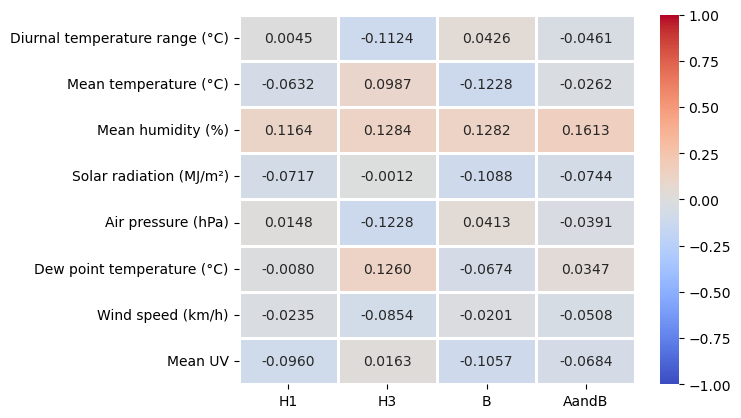

In [18]:
# sperman rank correlation is used as the relation is not linear
corr_df = df.drop(["Year", "Week", "From", "Seasonality"], axis=1).corr(method="spearman")
corr_df = corr_df.loc[mete_col, flu_col]

sns.heatmap(corr_df, annot=True, cmap="coolwarm", vmin=-1, vmax=1, fmt=".4f", linewidth=1)
plt.show()

&emsp;**b. Correlation between the delayed value of meteorological factors and different types of influenza detections**

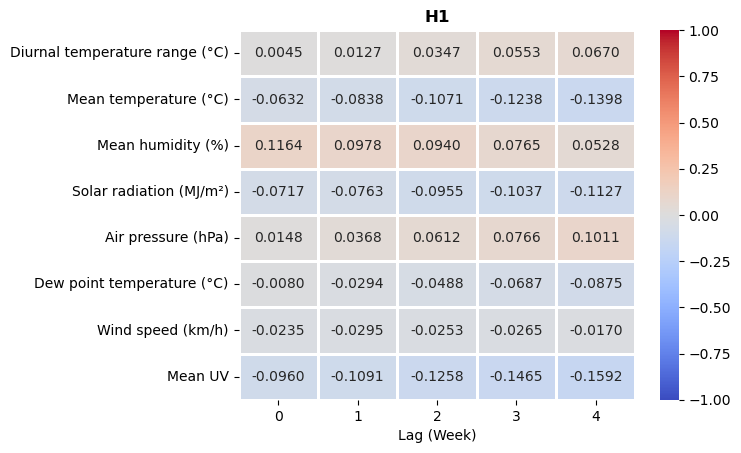

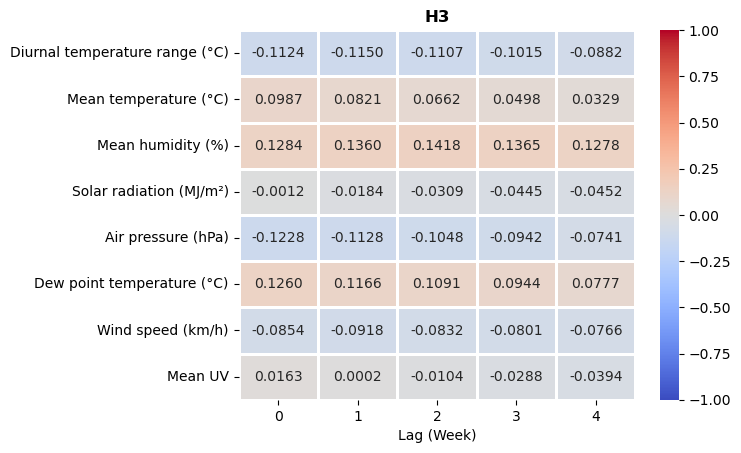

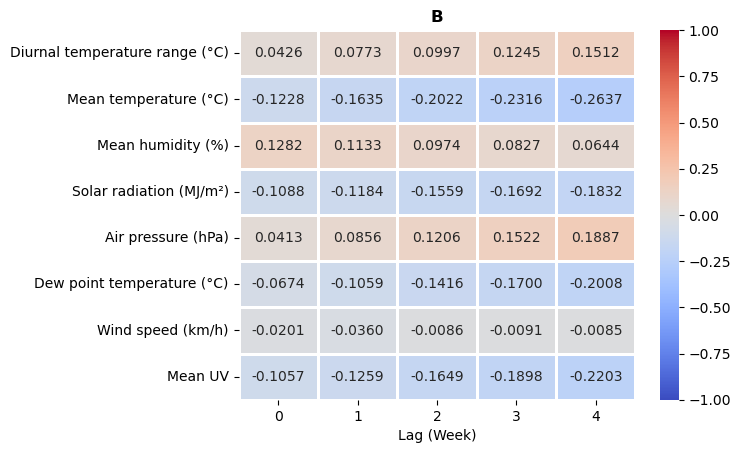

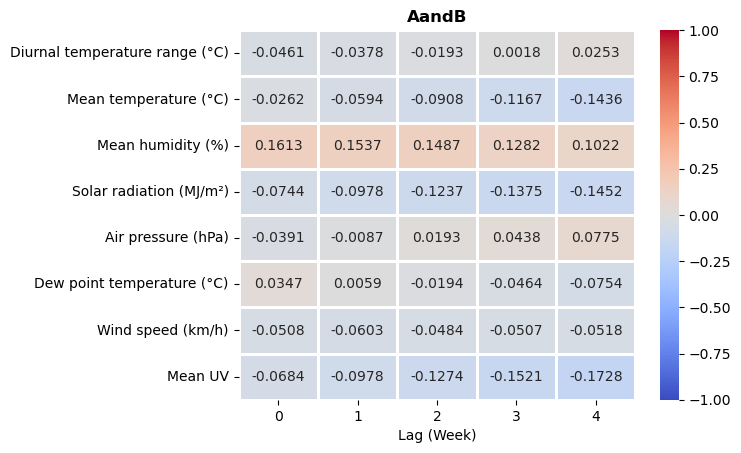

In [19]:
for flu in flu_col:
    corr_lst_lst = []
    for mete in mete_col:
        corr_lst = []
        lags = [0, 1, 2, 3, 4]
        for lag in lags:
            x_lagged = df[mete].shift(lag)
            temp = pd.concat([df[flu], x_lagged], axis=1).dropna()
            corr = temp[flu].corr(temp[mete], method="spearman")
            corr_lst.append(corr)
        corr_lst_lst.append(corr_lst)

    sns.heatmap(pd.DataFrame(corr_lst_lst, index=mete_col), annot=True, cmap="coolwarm", vmin=-1, vmax=1, fmt=".4f", linewidth=1)
    plt.xlabel("Lag (Week)")
    plt.title(flu, fontweight="bold")
    plt.show()

---
### **6. Collinearity / Multicollinearity Checking**
**Interpertations**

&emsp;**a. Test with spearman rank correlation**

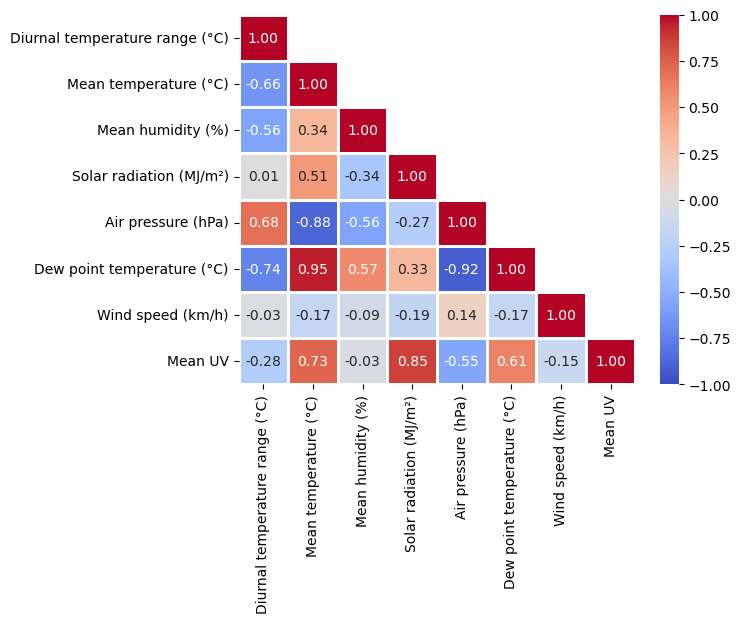

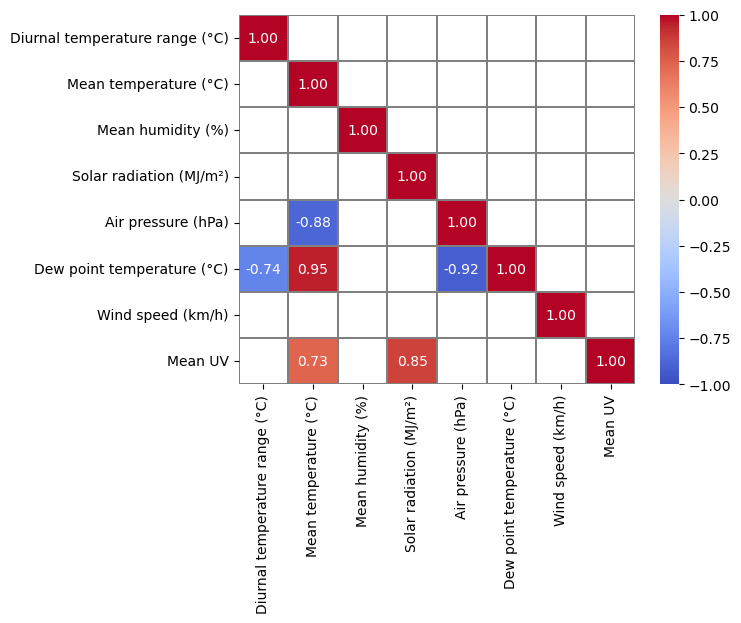

In [20]:
corr_weather = df[mete_col].corr(method="spearman")

for i in range(0, 8):
    for j in range(i+1, 8):
        corr_weather.iloc[i, j] = np.nan

sns.heatmap(corr_weather, annot=True, cmap="coolwarm", vmin=-1, vmax=1, fmt=".2f", linewidth=1)
plt.show()

for i in range(7, 0, -1):
    for j in range(i-1, -1, -1):
            if ((corr_weather.iloc[i, j] < 0.7) and (corr_weather.iloc[i, j] > -0.7)):
                corr_weather.iloc[i, j] = np.nan

sns.heatmap(corr_weather, annot=True, cmap="coolwarm", vmin=-1, vmax=1, fmt=".2f", linewidth=0.1, linecolor="gray")
plt.show()


&emsp;**b. Test with Variance Inflation Factor (VIF)**

In [21]:
# Test for mutlicollinearity with VIF
X = df[mete_col]

vif_df = pd.DataFrame({
    "Variable": X.columns,
    "VIF": [
        variance_inflation_factor(X.values, i)
        for i in range(X.shape[1])
    ]
}).sort_values("VIF", ascending=False)
display(vif_df)

while (vif_df["VIF"] > 5).any():
    mete_col.remove(vif_df.loc[0, "Variable"])
    X = df[mete_col]

    vif_df = pd.DataFrame({
        "Variable": X.columns,
        "VIF": [
            variance_inflation_factor(X.values, i)
            for i in range(X.shape[1])
        ]
    }).sort_values("VIF", ascending=False)

display(vif_df)
print(f"Final mete list: {mete_col}")


,Variable,VIF
5,Dew point temperature (°C),134.747528
1,Mean temperature (°C),95.874813
2,Mean humidity (%),17.686105
3,Solar radiation (MJ/m²),7.610842
7,Mean UV,7.298033
4,Air pressure (hPa),5.342290
0,Diurnal temperature range (°C),2.442852
6,Wind speed (km/h),1.141350


,Variable,VIF
2,Mean UV,1.470198
0,Dew point temperature (°C),1.465568
1,Wind speed (km/h),1.017486


Final mete list: ['Dew point temperature (°C)', 'Wind speed (km/h)', 'Mean UV']
